In [13]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [3]:
#import data
offm1 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_m1offset.fits')
offm05 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_m05offset.fits')
offm03 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_m03offset.fits')
offm01 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_m01offset.fits')
off0 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_0offset.fits')
off01 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_01offset.fits')
off03 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_03offset.fits')
off05 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_05offset.fits')
off1 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_1offset.fits')

In [4]:
sweep = [offm1, offm05, offm03, offm01, off0, off01, off03, off05, off1]

In [10]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

In [161]:
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(len(data))
    popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

def slice_speckle_angle(img,speckle_number,print_updates=False):
    #locate the general area of the speckle
    extent=20
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    #print(speckle_center)

    #cut out the speckle area
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
    speckle_img = rect * img

    #find the center of intensity of the speckle area and window the image around that center
    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=50
    new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)
    #imshow_field(new_img)
    
    shaped = new_img.shaped
    mus = np.zeros(shaped.shape[0])

    snr_threshold = 2

    for i in range(shaped.shape[0]): #in np.array([40,0]):
        if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
            sliced = shaped[:,i]
        else: sliced = shaped[i,:]

        zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)

        if zscore > snr_threshold:
            s = isolate_gaussian(sliced)
            s /= s.max()
            m, std, fwhm = mu(s)
            mus[i] = m
        else: mus[i] = -1

    deriv2 = np.gradient(np.gradient(mus))

    nonlin_region = np.atleast_1d(np.squeeze(np.where(np.abs(deriv2) >= 0.4)))
    #print(type(nonlin_region))

    midpoint = int(np.floor(window_size / 2))
    leftbound = nonlin_region[nonlin_region < midpoint][-1] if any(nonlin_region < midpoint) else None
    rightbound = nonlin_region[nonlin_region > midpoint][0] if any(nonlin_region > midpoint) else None

    if leftbound is not None and rightbound is not None:
        linear_region = mus[leftbound:rightbound]
        lin_x = np.arange(len(linear_region))

        m , b = np.polyfit(lin_x,linear_region,deg=1)
        angle = np.arctan(m)
        if print_updates ==True:
            print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')

        return np.degrees(angle)
    else: 
        if print_updates == True:
            print(f'unable to fit speckle {speckle_number}')
        return np.nan


#now find the speckle angles for all four 
def all_speckle_angles(img):
    angles = np.zeros(4)
    for i in range(4):
        #print(i)
        angles[i] = slice_speckle_angle(img,i)
    return angles

In [173]:
#filter all the image cubes from each step
filtered_sweep = [] #filtered image cube at each step
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = [] 

for j, step in enumerate(sweep):
    img_cube = []
    diff13 = []
    diff24 = []
    for i, field in enumerate(step):
        filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=60)) 
        #filtered = Field(np.array([x if x > 0 else 0 for x in filtered ]),filtered.grid)
        img_cube.append(filtered)
        a = all_speckle_angles(filtered)
        diff13.append(a[0] - a[2])
        diff24.append(a[1] - a[3])
    diffs13_list.append(diff13)
    diffs24_list.append(diff24)
    filtered_sweep.append(img_cube)

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_87371/314129785.py:4: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


In [179]:
#now to find the mean and std for each speckle pair at each adc angle
avgs13 = np.zeros(len(diffs13_list))
stds13 = np.zeros(len(diffs13_list))

avgs24 = np.zeros(len(diffs13_list))
stds24 = np.zeros(len(diffs13_list))

for i, angle in enumerate(diffs13_list):
    angle = np.array(angle)
    avgs13[i] = np.nanmean(angle)
    stds13[i] = np.nanstd(angle)

for i, angle in enumerate(diffs24_list):
    angle = np.array(angle)
    avgs24[i] = np.nanmean(angle)
    stds24[i] = np.nanstd(angle)

Slope of Speckles 1&3 Response: -2.1547167747872824
Offset of Speckles 1&3 Response: -0.3581151509673279
Slope of Speckles 2&4 Response: 3.803334849676951
Offset of Speckles 2&4 Response: 2.582246885651145


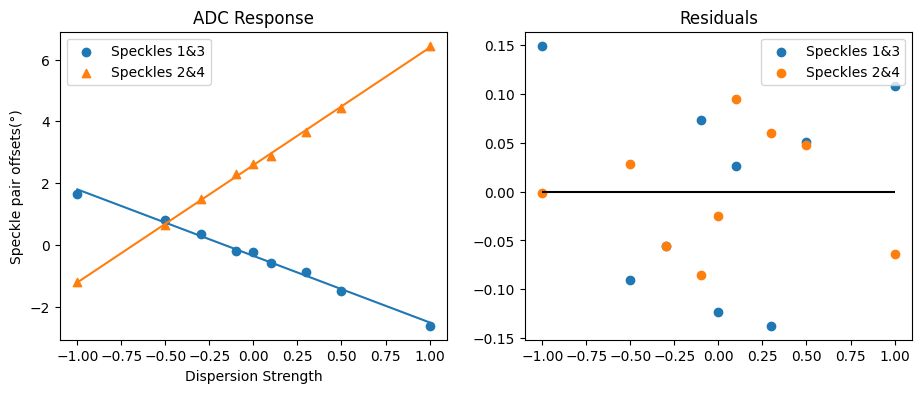

In [189]:
#plot the linear response
offsets = np.array([-1, -0.5, -0.3, -0.1, 0, 0.1, 0.3, 0.5, 1])

b1 = np.zeros(2)
m1 = np.zeros(2)
residuals = np.zeros(shape=(2,len(avgs13)))

avgs = [avgs13, avgs24]

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets,avgs[j],deg=1)
    plt.scatter(offsets, avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets
    residuals[j,:] =  linepoints - avgs[j]
    plt.plot(offsets, linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')


plt.title('ADC Response')
plt.xlabel('Dispersion Strength')
plt.ylabel('Speckle pair offsets(°)')
plt.legend()

plt.subplot(1,2,2)
plt.scatter(offsets,residuals[0,:], label=labels[0])
plt.scatter(offsets,residuals[1,:], label=labels[1])
plt.hlines(0,-1,1,colors='black')
plt.legend()
plt.title('Residuals')
plt.show()

In [190]:
#finding the response/control matrices
response = np.matrix([m1])
ctrl_matrix = np.linalg.pinv(response)
print(ctrl_matrix.T)

ctrl_matrix = ctrl_matrix.T
print(ctrl_matrix[0,1])

[[-0.11276422  0.19904244]]
0.19904243937441812


In [191]:
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq)
ADC.set_control_mtx(ctrl_matrix)

In [194]:
avgs = np.matrix(avgs)
commands = np.zeros(len(avgs13))

for i in range(len(avgs13)):
    commands[i] = ADC.calculate_command(avgs[:,i].T)

print(commands)


[ 0.42861805 -0.03848504 -0.25923908 -0.47956856 -0.54543233 -0.63851751
 -0.826918   -1.05053054 -1.57916063]


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_87371/4267084774.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  commands[i] = ADC.calculate_command(avgs[:,i].T)


slope: -1.0000000000000002
offset: -0.5543592944127143


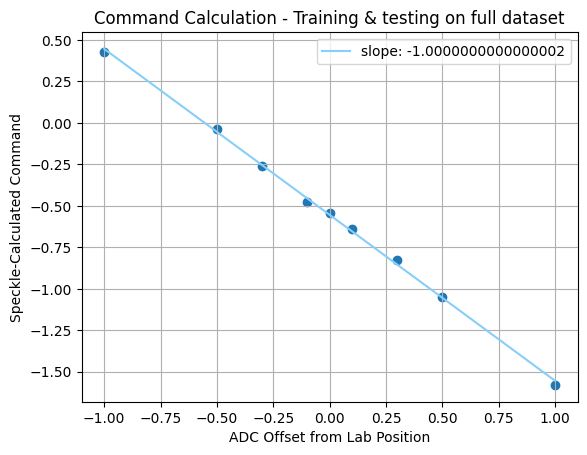

In [195]:
#plotting versus the actual angles:
m, b = np.polyfit(offsets,commands,deg=1)

print(f'slope: {m}')
print(f'offset: {b}')

plt.scatter(offsets,commands)
plt.plot(offsets, m * offsets + b,color='lightskyblue',label=f'slope: {m}')
plt.title('Command Calculation - Training & testing on full dataset')
plt.xlabel('ADC Offset from Lab Position')
plt.ylabel('Speckle-Calculated Command')
plt.legend()
plt.grid()
plt.show()